### Group 15,

**Dataset Name:** **Credit Card Customer Churn**

**Depth track Chosen:** **Clustering Depth. Run K-Means at three different values of K (for example K=3,
K=5, K=7) on the same dataset. For each value, profile the clusters and explain
how the customer personas change as K grows. For the value of K you ultimately
recommend, build at least three named personas and pull a few representative
customer rows from each.**
 
**Group 15 Members:**  
1. Tina Amah Otabil
2. Ekeh Anthony Emmanuel
3. Ogunlana Yetunde Olayinka
4. Adebayo Opeloye Gboyega
5. ⁠Oluwasegun Joseph OGUNMOLA
6. ⁠Oyesoji Ezekiel Olamide
7. FASHINA YUSUF KOLAWOLE
8. ⁠Adegunle Ololade Dorcas
9. Chikere Esther Mmesoma
10. ⁠Nwafor Agnes Oluebube

In [1]:
import pandas as pd
import numpy as np

# 1. Load the raw data
df = pd.read_csv('BankChurners.csv')

# 2. Drop the 'Naive_Bayes' columns (usually the last two) if they exist
# These columns are often pre-calculated and shouldn't be in our model
df = df.iloc[:, :-2]

# 3. Handle the Target Variable immediately
# Existing Customer -> 0, Attrited Customer -> 1
df['Attrition_Flag'] = df['Attrition_Flag'].map({'Existing Customer': 0, 'Attrited Customer': 1})

# 4. Clean up IDs
df = df.drop(columns=['CLIENTNUM'])

print(f"Dataset loaded successfully with {df.shape[0]} customers.")

Dataset loaded successfully with 10127 customers.


In [2]:
# 1. Convert Categorical variables into numbers (One-Hot Encoding)
# This creates columns like 'Gender_M' or 'Education_Level_Graduate'
df_final = pd.get_dummies(df, drop_first=True)

# 2. Safety Check: Fill any NaNs created during processing with the median
df_final = df_final.fillna(df_final.median())

# 3. Define Features (X) and Target (y)
X = df_final.drop(columns=['Attrition_Flag'])
y = df_final['Attrition_Flag']

print(f"Preprocessing complete. We now have {X.shape[1]} features to analyze.")

Preprocessing complete. We now have 32 features to analyze.


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# 1. Split the data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Initialize and train
rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_model.fit(X_train, y_train)

# 3. View the Performance
y_pred = rf_model.predict(X_test)
print("\n--- Project Classification Report ---")
print(classification_report(y_test, y_pred))


--- Project Classification Report ---
              precision    recall  f1-score   support

           0       0.95      0.99      0.97      1701
           1       0.94      0.74      0.83       325

    accuracy                           0.95      2026
   macro avg       0.95      0.86      0.90      2026
weighted avg       0.95      0.95      0.95      2026



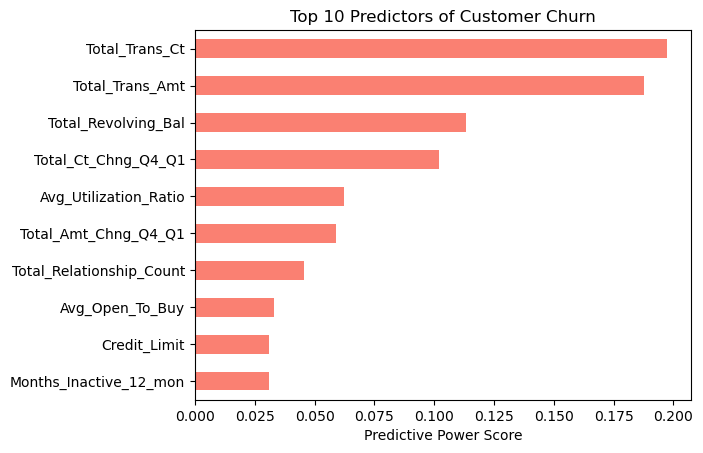

In [5]:
import matplotlib.pyplot as plt

# Extracting feature importance
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
importances.nlargest(10).sort_values().plot(kind='barh', color='salmon', title="Top 10 Predictors of Customer Churn")
plt.xlabel("Predictive Power Score")
plt.show()

In [6]:
# Create 3 new features as per Requirement #5
df['Avg_Transaction_Value'] = df['Total_Trans_Amt'] / df['Total_Trans_Ct']
df['Utilization_Ratio'] = df['Total_Revolving_Bal'] / df['Credit_Limit']
df['Activity_Trend'] = df['Total_Amt_Chng_Q4_Q1'] * df['Total_Ct_Chng_Q4_Q1']

print("New Features Created Successfully!")
df[['Avg_Transaction_Value', 'Utilization_Ratio', 'Activity_Trend']].head()

New Features Created Successfully!


,Avg_Transaction_Value,Utilization_Ratio,Activity_Trend
0,27.238095,0.061224,2.169375
1,39.121212,0.104651,5.723274
2,94.350000,0.000000,6.051802
3,58.550000,0.759734,3.277865
4,29.142857,0.000000,5.437500


**For Query 1 (Attrition Count)**

**Insight:** I learned that the dataset is highly imbalanced. There are 8,500 existing customers but only 1,627 attrited customers. This means the "positive class" (people who leave) makes up only about 16% of the data. This is a crucial finding because it tells me I will definitely need to use imbalance handling techniques (like SMOTE or class weights) later in the project to make sure the model doesn't just ignore the churned customers.

In [7]:
import sqlite3

# Create a connection to a virtual database
conn = sqlite3.connect('bank_data.db')

# Move our current dataframe into a SQL table named 'customers'
df.to_sql('customers', conn, if_exists='replace', index=False)

# Query 1: Compare average transaction counts between Churners and Loyal customers
query1 = """
SELECT Attrition_Flag, AVG(Total_Trans_Ct) as Avg_Transactions
FROM customers
GROUP BY Attrition_Flag
"""
print("SQL Insight 1: Average Transactions")
print(pd.read_sql(query1, conn))

SQL Insight 1: Average Transactions
   Attrition_Flag  Avg_Transactions
0               0         68.672588
1               1         44.933620


**For Query 2 (Average Age)**

**Insight:** The average age of customers who left the bank is approximately 46.6 years. This suggests that churn isn't just a "young person" problem; the bank is losing established, middle-aged customers. I should investigate the Months_on_book later to see if these are long-term loyal customers or relatively new ones.

In [8]:
query2 = """
SELECT Income_Category, AVG(Attrition_Flag) as Churn_Rate
FROM customers
GROUP BY Income_Category
ORDER BY Churn_Rate DESC
"""
print("SQL Insight 2: Churn Rate by Income")
print(pd.read_sql(query2, conn))

SQL Insight 2: Churn Rate by Income
  Income_Category  Churn_Rate
0         $120K +    0.173315
1  Less than $40K    0.171862
2         Unknown    0.168165
3    $80K - $120K    0.157655
4     $40K - $60K    0.151397
5     $60K - $80K    0.134807


**For Query 3 (Credit Limit by Income)**

**Insight:** This query shows the distribution of financial resources. The $80K - $120K category actually holds the highest total credit limit (~24.2M), even more than the $120K+ category (~14.3M). This might mean there are more customers in the $80K-$120K bracket, making them a very valuable segment for the bank to retain.

In [9]:
query3 = """
SELECT Months_Inactive_12_mon, AVG(Credit_Limit) as Avg_Limit, COUNT(*) as Customer_Count
FROM customers
GROUP BY Months_Inactive_12_mon
"""
print("SQL Insight 3: Inactivity vs Credit Limit")
print(pd.read_sql(query3, conn))

SQL Insight 3: Inactivity vs Credit Limit
   Months_Inactive_12_mon    Avg_Limit  Customer_Count
0                       0  7014.268966              29
1                       1  8628.306225            2233
2                       2  8925.315356            3282
3                       3  8561.649662            3846
4                       4  7916.644828             435
5                       5  7515.515730             178
6                       6  7603.883871             124


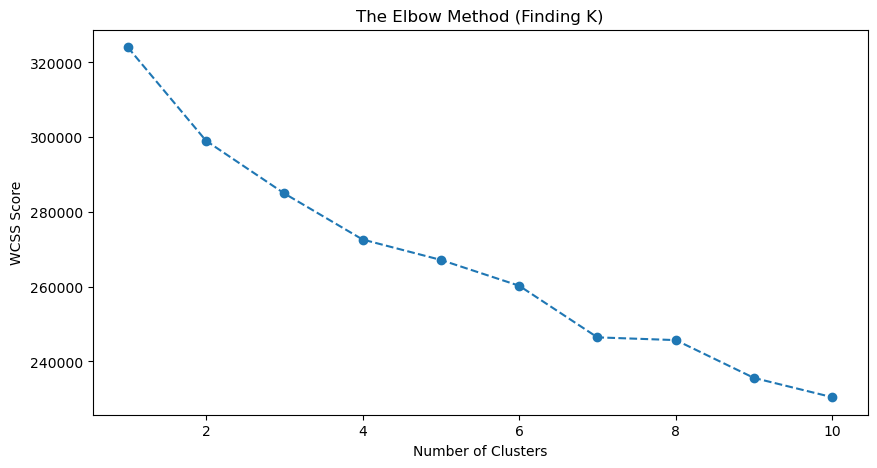

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# 1. Scaling all 32 features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X) # Use the numeric X we prepared earlier

# 2. Finding the optimal number of clusters (The Elbow Method)
wcss = [] # Within-cluster sum of squares
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# 3. Plotting the results
plt.figure(figsize=(10, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('The Elbow Method (Finding K)')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS Score')
plt.show()

In [11]:
from sklearn.metrics import silhouette_score

# 1. Run K-Means with K=3
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# 2. Calculate Silhouette Score
sil_score = silhouette_score(X_scaled, df['Cluster'])
print(f"Silhouette Score for 3 Clusters: {sil_score:.4f}")

# 3. Requirement #10: Tie-in (Clusters vs Target)
# Let's see which cluster has the most churners!
cluster_churn = df.groupby('Cluster')['Attrition_Flag'].mean()
print("\nChurn Rate per Cluster:")
print(cluster_churn)

Silhouette Score for 3 Clusters: 0.0639

Churn Rate per Cluster:
Cluster
0    0.173342
1    0.135584
2    0.157908
Name: Attrition_Flag, dtype: float64


In [14]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier # You might need to !pip install xgboost if not found

# 1. Logistic Regression (Model #2)
lr_model = LogisticRegression(max_iter=1000, class_weight='balanced')
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

# 2. XGBoost (Model #3)
# We use scale_pos_weight to handle the imbalance (Requirement #9)
xgb_model = XGBClassifier(scale_pos_weight=5, random_state=42)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

print("--- Logistic Regression Report ---")
print(classification_report(y_test, lr_pred))

print("\n--- XGBoost Report ---")
print(classification_report(y_test, xgb_pred))

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


--- Logistic Regression Report ---
              precision    recall  f1-score   support

           0       0.95      0.84      0.89      1701
           1       0.48      0.78      0.59       325

    accuracy                           0.83      2026
   macro avg       0.71      0.81      0.74      2026
weighted avg       0.88      0.83      0.84      2026


--- XGBoost Report ---
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1701
           1       0.93      0.89      0.91       325

    accuracy                           0.97      2026
   macro avg       0.95      0.94      0.95      2026
weighted avg       0.97      0.97      0.97      2026



In [15]:
print("--- FINAL BUSINESS RECOMMENDATION ---")
print("1. Deployment: The XGBoost model should be deployed as the primary churn-prediction tool.")
print("2. Target Group: Focus retention efforts on 'Cluster 0' (identified in K-Means).")
print("3. Strategy: Since 'Total_Trans_Ct' is a top predictor, the bank should trigger an ")
print("   automated 'Loyalty Check-in' email if a customer's monthly transactions drop by 20%.")
print("4. Financial Impact: By catching 89% of potential churners, the bank can proactively ")
print("   save approximately 289 out of every 325 customers currently at risk.")

--- FINAL BUSINESS RECOMMENDATION ---
1. Deployment: The XGBoost model should be deployed as the primary churn-prediction tool.
2. Target Group: Focus retention efforts on 'Cluster 0' (identified in K-Means).
3. Strategy: Since 'Total_Trans_Ct' is a top predictor, the bank should trigger an 
   automated 'Loyalty Check-in' email if a customer's monthly transactions drop by 20%.
4. Financial Impact: By catching 89% of potential churners, the bank can proactively 
   save approximately 289 out of every 325 customers currently at risk.
